# 04 Spatial

## Question

Earlier notebooks show NO₂ varies by location. That is a statement about 15
measured points across 892 km². This notebook asks how far a measurement
travels, and what the city's own model adds between the stations.

## Method

- **Part A.** Leave-one-out inverse distance weighting. Hide each station,
  estimate its annual mean from the others weighted by 1/d², compare to the
  measured value. Both pollutants, sensitivity across weighting powers
- **Part B.** Berlin's FAirQ model, 2025 annual means on a 50 × 50 m grid.
  Value at each station against the measurement and against Part A. Then a
  systematic sample across the city for compliance by area

In [22]:
import json
import time
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# One colour system across notebooks.
# Hue = pollutant. Blue/orange is CVD safe.
COLOUR = {"no2": "#4c72b0", "pm2": "#dd8452"}
PALE   = {"no2": "#b8c6de", "pm2": "#f0cab5"}
CMAP   = {"no2": "mako_r", "pm2": "flare"}

CURRENT = {"no2": 40, "pm2": 25}    # annual mean, in force 2025
LIMIT   = {"no2": 20, "pm2": 10}    # annual mean, EU 2030
WHO     = {"no2": 10, "pm2": 5}

# $_2$ renders the subscript. The plain ₂ character draws as a box in figures.
LABEL = {
    "no2": "NO$_2$ · mainly traffic exhaust · airways",
    "pm2": "PM2.5 · fine particles · heart and blood vessels",
}

NAME = {
    "mc010": "Amrumer Str., Wedding",
    "mc027": "Schichauweg, Marienfelde",
    "mc032": "Grunewald, Charlottenburg-Wilmersdorf",
    "mc042": "Nansenstr., Neukölln",
    "mc077": "Buch, Pankow",
    "mc085": "Friedrichshagen, Treptow-Köpenick",
    "mc117": "Schildhornstr., Steglitz",
    "mc124": "Mariendorfer Damm, Mariendorf",
    "mc144": "Silbersteinstr., Neukölln",
    "mc145": "Frohnau, Reinickendorf",
    "mc171": "Brückenstr., Mitte",
    "mc174": "Frankfurter Allee, Friedrichshain",
    "mc190": "Leipziger Str., Mitte",
    "mc221": "Karl-Marx-Str., Neukölln",
    "mc282": "Karlshorst, Lichtenberg",
}

TYPE = {
    "mc010": "background", "mc042": "background",
    "mc171": "background", "mc282": "background",
    "mc027": "suburb", "mc032": "suburb", "mc077": "suburb",
    "mc085": "suburb", "mc145": "suburb",
    "mc117": "traffic", "mc124": "traffic", "mc144": "traffic",
    "mc174": "traffic", "mc190": "traffic", "mc221": "traffic",
}

# Cleaned table from 01. Drops and fireworks flag already applied.
# CSV stores the offset as text, so parse to UTC then convert, as in 01.
ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "data" / "processed" / "hourly.csv")
df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_convert("Europe/Berlin")
df["fireworks"] = df["fireworks"].astype(bool)      # survives CSV as text otherwise
RAW = ROOT / "data" / "raw"
RAW.mkdir(parents=True, exist_ok=True)

print(df.shape)

(236180, 7)


## Part A · How far a measurement travels

In [23]:
# Station coordinates are not in the hourly data. One request to /api/stations,
# cached like the measurement files so the notebook reruns without the network.
path = RAW / "stations.json"

if path.exists():
    stations = json.loads(path.read_text())
else:
    with urlopen("https://luftdaten.berlin.de/api/stations?active=true") as r:
        text = r.read().decode()
    path.write_text(text)
    stations = json.loads(text)

print(len(stations), "stations")

15 stations


In [24]:
# Build a station table from the API: coordinates, group, and whether a
# measuring height is published. Strings to floats; lat/lng are WGS84.
st = pd.DataFrame(
    [
        {
            "station": s["code"],
            "name": s["name"],
            "lat": float(s["lat"]),
            "lng": float(s["lng"]),
            "group": s["stationgroups"][0] if s["stationgroups"] else None,
            "height": s["measuringHeight"],
        }
        for s in stations
    ]
).set_index("station")

print(st["group"].value_counts())
print("heights published:", st["height"].notna().sum(), "of", len(st))
print(st[["lat", "lng"]].agg(["min", "max"]))
st

group
traffic       6
suburb        5
background    4
Name: count, dtype: int64
heights published: 3 of 15
          lat       lng
min  52.39840  13.22514
max  52.65327  13.64705


,name,lat,lng,group,height
station,,,,,
mc010,010 Wedding,52.542910,13.349260,background,NaN
mc027,027 Marienfelde,52.398400,13.368075,suburb,NaN
mc032,032 Grunewald,52.473190,13.225140,suburb,3.0
mc042,042 Neukölln,52.489451,13.430844,background,NaN
mc077,077 Buch,52.644100,13.483300,suburb,NaN
mc085,085 Friedrichshagen,52.447697,13.647050,suburb,NaN
mc117,117 Schildhornstraße,52.463620,13.318320,traffic,NaN
mc124,124 Mariendorfer Damm,52.438115,13.387720,traffic,NaN
mc145,145 Frohnau,52.653270,13.296080,suburb,NaN


Three stations publish a measuring height: Karl-Marx-Str. 40 m, Leipziger Str.
35 m, Grunewald 3 m. Twelve report null. `stationgroups` matches the TYPE dict
in 02 and 03 (6 traffic, 5 suburb, 4 background).

In [25]:
# Distance between every pair of stations in km, from WGS84 coordinates.
# Haversine: accurate to metres over a city.
lat = np.radians(st["lat"].to_numpy())
lng = np.radians(st["lng"].to_numpy())
a = (np.sin((lat[:, None] - lat[None, :]) / 2) ** 2
     + np.cos(lat[:, None]) * np.cos(lat[None, :])
     * np.sin((lng[:, None] - lng[None, :]) / 2) ** 2)
dist = pd.DataFrame(6371 * 2 * np.arcsin(np.sqrt(a)), index=st.index, columns=st.index)

# Nearest other station: how dense the network really is.
nearest = dist.replace(0, np.nan).min()
print(nearest.round(1).sort_values())
print("median nearest neighbour:", round(nearest.median(), 1), "km")

station
mc042     0.6
mc221     0.6
mc144     2.0
mc171     2.5
mc190     2.5
mc174     3.5
mc010     4.3
mc027     4.6
mc124     4.6
mc282     5.1
mc117     5.5
mc032     6.4
mc085     9.0
mc077    12.7
mc145    12.7
dtype: float64
median nearest neighbour: 4.6 km


In [26]:
# Annual mean per station. These are the values the holdout tries to recover.
ann = df.groupby(["core", "station"])["value"].mean().rename("measured").reset_index()
ann["group"] = ann["station"].map(st["group"])
ann["name"] = ann["station"].map(NAME)

In [27]:
# Hide one station, estimate it from the others weighted by 1/d^power,
# compare to what it measured. Repeat for every station.
def loo_idw(core, power=2):
    g = ann[ann["core"] == core].set_index("station")
    rows = []
    for s in g.index:
        others = g.index.drop(s)
        w = 1 / dist.loc[s, others] ** power
        pred = (w * g.loc[others, "measured"]).sum() / w.sum()
        rows.append((s, g.loc[s, "measured"], pred))
    r = pd.DataFrame(rows, columns=["station", "measured", "predicted"]).set_index("station")
    r["error"] = r["predicted"] - r["measured"]
    r["core"] = core
    return r

res = pd.concat([loo_idw("no2"), loo_idw("pm2")])
res["group"] = res.index.map(st["group"])
res["name"] = res.index.map(NAME)

In [28]:
# Mean absolute error, and the same as a share of the pollutant's mean,
# so NO₂ and PM2.5 compare despite their different levels.
summary = res.groupby("core").agg(
    mae=("error", lambda e: e.abs().mean()),
    max_ae=("error", lambda e: e.abs().max()),
    mean=("measured", "mean"),
)
summary["mae_pct"] = summary["mae"] / summary["mean"] * 100
print(summary.round(1))

# Signed error by station type. Negative means interpolation underestimates.
print(res.groupby(["core", "group"])["error"].mean().round(1))

      mae  max_ae  mean  mae_pct
core                            
no2   7.1    12.6  16.1     44.0
pm2   1.6     3.7  11.5     13.5
core  group     
no2   background    5.0
      suburb        9.9
      traffic      -5.3
pm2   background    1.0
      suburb        3.1
      traffic      -0.7
Name: error, dtype: float64


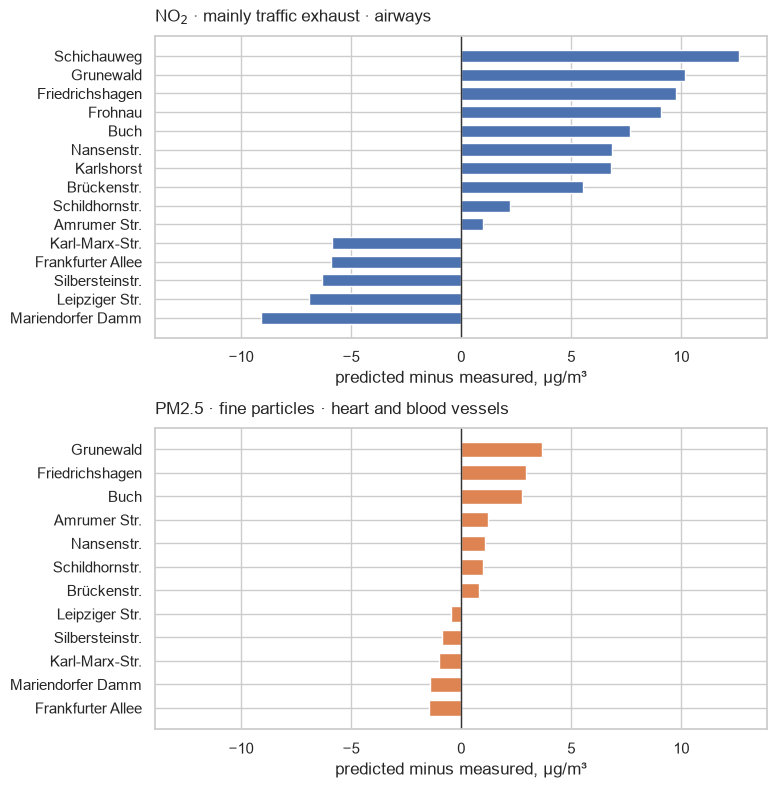

In [29]:
# Prediction error per station. Negative: interpolation reads it too low.
# Same x scale in both panels so the pollutants compare directly.
lim = res["error"].abs().max() * 1.1
fig, axes = plt.subplots(2, 1, figsize=(9, 9))

for ax, core in zip(axes, ["no2", "pm2"]):
    g = res[res["core"] == core].sort_values("error")
    ax.barh(g["name"].str.split(", ").str[0], g["error"], color=COLOUR[core], height=0.65)
    ax.axvline(0, color="#333333", lw=1)
    ax.set_xlim(-lim, lim)
    ax.set_title(LABEL[core], pad=10, loc="left")
    ax.set_xlabel("predicted minus measured, µg/m³")

plt.subplots_adjust(left=0.28, right=0.96, hspace=0.3)
plt.savefig(ROOT / "figures" / "04_holdout_error.png", dpi=150, pad_inches=0.3)

In [30]:
# Does the result depend on the method? Power 1 spreads influence widely,
# power 6 trusts the nearest station almost entirely.
sens = pd.DataFrame({
    f"power {p}": pd.concat([loo_idw("no2", p), loo_idw("pm2", p)])
                    .groupby("core")["error"].apply(lambda e: e.abs().mean())
    for p in [1, 2, 3, 6]
}).round(1)
sens

,power 1,power 2,power 3,power 6
core,,,,
no2,6.6,7.1,7.4,7.8
pm2,1.5,1.6,1.6,1.6


## Part B · The city model

Berlin publishes the FAirQ model for 2025 as a WMS at
`gdi.berlin.de/services/wms/ua_luftschadstoffbelastung_2025`: NO₂, PM10 and
PM2.5 annual means on a 50 × 50 m grid. The matching WFS lists no layers, so the
grid cannot be downloaded as features. The WMS layers are queryable, so values
are read point by point.

The model is fitted with measurements. Agreement at the stations is partly
built in; disagreement is the informative part.

In [31]:
# FAirQ model, 2025 annual means on a 50 x 50 m grid.
# One request per pollutant and point. Twice the requests, but easy to read.
WMS = "https://gdi.berlin.de/services/wms/ua_luftschadstoffbelastung_2025"
LAYER = {"no2": "a_pollutant_grid_avg_no2_2025",
         "pm2": "c_pollutant_grid_avg_pm2_5_2025"}


def model_value(core, lat, lng):
    """Model value in the 50 m cell under a point. None outside the grid."""
    layer = LAYER[core]
    q = ("service=WMS&version=1.3.0&request=GetFeatureInfo"
         f"&layers={layer}&query_layers={layer}&styles="
         f"&crs=EPSG:4326&bbox={lat-0.0005},{lng-0.0005},{lat+0.0005},{lng+0.0005}"
         "&width=101&height=101&i=50&j=50&info_format=application/json")
    with urlopen(f"{WMS}?{q}", timeout=60) as r:
        body = r.read()
    try:
        feats = json.loads(body)["features"]
    except ValueError:                  # empty or non-JSON answer: outside the grid
        return None
    if not feats:
        return None
    value = list(feats[0]["properties"].values())[0]
    return float(value) if value else None


print(model_value("no2", st.loc["mc124", "lat"], st.loc["mc124", "lng"]))   # expect 28.0
print(model_value("pm2", st.loc["mc124", "lat"], st.loc["mc124", "lng"]))

28.0
15.0


In [32]:
# Model value at each station, both pollutants, cached. 30 requests.
path = RAW / "model_at_stations.json"

if path.exists():
    at_st = json.loads(path.read_text())
else:
    at_st = {s: {c: model_value(c, r["lat"], r["lng"]) for c in ["no2", "pm2"]}
             for s, r in st.iterrows()}
    path.write_text(json.dumps(at_st, indent=1))

res["model"] = [at_st[s][c] for s, c in zip(res.index, res["core"])]
res["model_error"] = res["model"] - res["measured"]
print(res[["name", "core", "measured", "model", "model_error", "error"]].round(1).to_string())

                                          name core  measured  model  model_error  error
station                                                                                 
mc010                    Amrumer Str., Wedding  no2      18.0   18.0         -0.0    1.0
mc027                 Schichauweg, Marienfelde  no2       8.4   11.0          2.6   12.6
mc032    Grunewald, Charlottenburg-Wilmersdorf  no2       7.8   12.0          4.2   10.2
mc042                     Nansenstr., Neukölln  no2      15.2   17.0          1.8    6.9
mc077                             Buch, Pankow  no2       9.2   12.0          2.8    7.7
mc085        Friedrichshagen, Treptow-Köpenick  no2       7.8   11.0          3.2    9.8
mc117                 Schildhornstr., Steglitz  no2      16.2   24.0          7.8    2.2
mc124            Mariendorfer Damm, Mariendorf  no2      26.3   28.0          1.7   -9.1
mc144                Silbersteinstr., Neukölln  no2      25.7   28.0          2.3   -6.3
mc145                

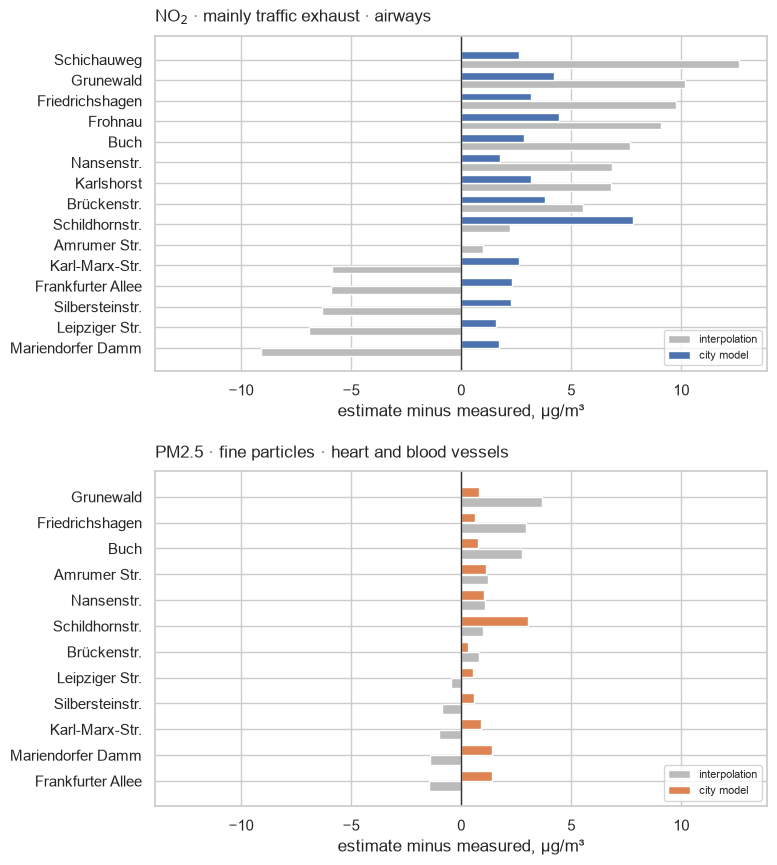

In [33]:
# Error per station, two methods. Grey: interpolation from the other stations.
# Colour: the city model. Same scale in both panels so the pollutants compare.
lim = res[["error", "model_error"]].abs().max().max() * 1.1
fig, axes = plt.subplots(2, 1, figsize=(9, 10))

for ax, core in zip(axes, ["no2", "pm2"]):
    g = res[res["core"] == core].sort_values("error")
    y = np.arange(len(g))
    ax.barh(y - 0.2, g["error"], height=0.38, color="#bbbbbb", label="interpolation")
    ax.barh(y + 0.2, g["model_error"], height=0.38, color=COLOUR[core], label="city model")
    ax.set_yticks(y)
    ax.set_yticklabels(g["name"].str.split(", ").str[0])
    ax.axvline(0, color="#333333", lw=1)
    ax.set_xlim(-lim, lim)
    ax.set_title(LABEL[core], pad=10, loc="left")
    ax.set_xlabel("estimate minus measured, µg/m³")
    ax.legend(loc="lower right", fontsize=8)

plt.subplots_adjust(left=0.28, right=0.96, hspace=0.3)
plt.savefig(ROOT / "figures" / "04_model_vs_interpolation.png", dpi=150, pad_inches=0.3)

In [34]:
# Mean absolute error and mean signed error, both methods.
# Signed error near zero means no overall bias; a positive value means reading high.
cmp = res.groupby("core").agg(
    model_mae=("model_error", lambda e: e.abs().mean()),
    model_bias=("model_error", "mean"),
    holdout_mae=("error", lambda e: e.abs().mean()),
)
print(cmp.round(1))

      model_mae  model_bias  holdout_mae
core                                    
no2         3.0         2.9          7.1
pm2         1.0         1.0          1.6


### Part B · City model

- The city model lands closer than interpolation: NO₂ mean absolute error
  3.0 µg/m³ against 7.1, PM2.5 1.0 against 1.6
- Its error is almost entirely a uniform offset: mean signed error +2.9 for NO₂
  and +1.0 for PM2.5. At no station does the model read below the measurement
- The model gets the spatial pattern right. Station type no longer predicts the
  error, as it did for interpolation
- Schildhornstr. is overestimated by 7.8 µg/m³ NO₂ and 3.0 PM2.5, more than
  twice the typical offset, by both methods
- Model values are whole numbers, a resolution of 1 µg/m³

### Open

- Why the model reads high is not established here

In [35]:
# Systematic sample of the model across Berlin: one point every 2 km.
# Points outside the city return no value and drop out. Saved after each row,
# so an interrupted run continues where it stopped.
STEP_KM = 2.0
lats = np.arange(52.33, 52.68, STEP_KM / 111.2)
lngs = np.arange(13.08, 13.77, STEP_KM / (111.2 * np.cos(np.radians(52.5))))

path = RAW / f"model_sample_{STEP_KM:g}km.json"
sample = json.loads(path.read_text()) if path.exists() else {}

for la in lats:
    for lo in lngs:
        key = f"{la:.5f},{lo:.5f}"
        if key not in sample:
            sample[key] = {c: model_value(c, la, lo) for c in ["no2", "pm2"]}
            time.sleep(0.1)
    path.write_text(json.dumps(sample))

grid = pd.DataFrame(sample.values()).dropna()
print(len(lats) * len(lngs), "points queried,", len(grid), "inside the model grid")

480 points queried, 422 inside the model grid


In [36]:
# Keep only sample points inside Berlin. The model grid extends into Brandenburg.
# Boundary from OpenStreetMap via Nominatim, keyless; its use policy asks for a User-Agent.
from urllib.request import Request

from matplotlib.path import Path as Outline

path = RAW / "berlin_boundary.json"
if path.exists():
    shape = json.loads(path.read_text())
else:
    req = Request("https://nominatim.openstreetmap.org/search?q=Berlin,Germany"
                  "&polygon_geojson=1&format=json&limit=1",
                  headers={"User-Agent": "berliner-luft-study"})
    with urlopen(req, timeout=60) as r:
        shape = json.loads(r.read())[0]["geojson"]
    path.write_text(json.dumps(shape))

# GeoJSON stores (longitude, latitude). The sample keys are "latitude,longitude".
parts = shape["coordinates"] if shape["type"] == "MultiPolygon" else [shape["coordinates"]]
outlines = [Outline(p[0]) for p in parts]          # outer ring of each part

pts = np.array([[float(k.split(",")[1]), float(k.split(",")[0])] for k in sample])
inside = np.any([o.contains_points(pts) for o in outlines], axis=0)

grid = pd.DataFrame([v for v, i in zip(sample.values(), inside) if i]).dropna()
print(inside.sum(), "of", len(pts), "points inside Berlin,", len(grid), "with values")

219 of 480 points inside Berlin, 215 with values


In [37]:
# Share of Berlin's area above each level, against the share of stations above.
# The model reads high at the stations by a mean offset (model_bias in cmp),
# so each area share is also shown with the level raised by that offset.
bias = cmp["model_bias"]
rows = []
for core in ["no2", "pm2"]:
    meas = ann.loc[ann["core"] == core, "measured"]
    for name, lvl in [("EU 2030", LIMIT[core]), ("WHO", WHO[core])]:
        rows.append({
            "pollutant": core,
            "level": f"{name} {lvl}",
            "stations_pct": (meas > lvl).mean() * 100,
            "area_pct": (grid[core] > lvl).mean() * 100,
            "area_pct_offset": (grid[core] > lvl + bias[core]).mean() * 100,
        })
area = pd.DataFrame(rows).round(0)
area

,pollutant,level,stations_pct,area_pct,area_pct_offset
0,no2,EU 2030 20,33.0,9.0,4.0
1,no2,WHO 10,67.0,97.0,67.0
2,pm2,EU 2030 10,75.0,71.0,47.0
3,pm2,WHO 5,100.0,100.0,100.0


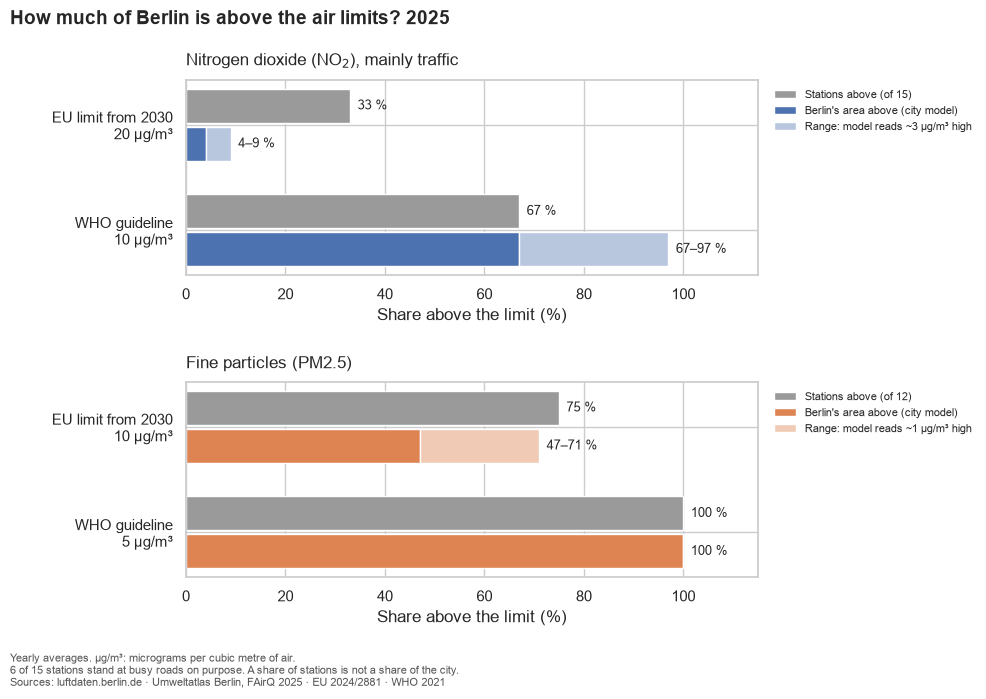

In [38]:
# Share above each limit: stations against Berlin's area.
# Area is a range: solid corrects for the model reading high, pale is the model as published.
PLAIN = {"no2": "Nitrogen dioxide (NO$_2$), mainly traffic",
         "pm2": "Fine particles (PM2.5)"}

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

for ax, core in zip(axes, ["no2", "pm2"]):
    g = area[area["pollutant"] == core].reset_index(drop=True)
    n = (ann["core"] == core).sum()
    y = np.arange(len(g))
    lo, hi = g["area_pct_offset"], g["area_pct"]

    ax.barh(y - 0.18, g["stations_pct"], height=0.32, color="#9a9a9a",
            label=f"Stations above (of {n})")
    ax.barh(y + 0.18, lo, height=0.32, color=COLOUR[core],
            label="Berlin's area above (city model)")
    ax.barh(y + 0.18, hi - lo, left=lo, height=0.32, color=PALE[core],
            label=f"Range: model reads ~{bias[core]:.0f} µg/m³ high")

    for yy, s in zip(y, g["stations_pct"]):
        ax.text(s + 1.5, yy - 0.18, f"{s:.0f} %", va="center", fontsize=9)
    for yy, a, b in zip(y, lo, hi):
        ax.text(b + 1.5, yy + 0.18, f"{a:.0f} %" if a == b else f"{a:.0f}–{b:.0f} %",
                va="center", fontsize=9)

    ax.set_yticks(y)
    ax.set_yticklabels([f"EU limit from 2030\n{LIMIT[core]} µg/m³",
                        f"WHO guideline\n{WHO[core]} µg/m³"])
    ax.invert_yaxis()
    ax.set_xlim(0, 115)
    ax.set_xlabel("Share above the limit (%)")
    ax.set_title(PLAIN[core], loc="left", pad=10)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, frameon=False)

fig.suptitle("How much of Berlin is above the air limits? 2025",
             x=0.02, ha="left", fontsize=14, fontweight="bold")

fig.text(0.02, 0.01, "\n".join([
    "Yearly averages. µg/m³: micrograms per cubic metre of air.",
    "6 of 15 stations stand at busy roads on purpose. A share of stations is not a share of the city.",
    "Sources: luftdaten.berlin.de · Umweltatlas Berlin, FAirQ 2025 · EU 2024/2881 · WHO 2021",
]), fontsize=8, color="#555555", va="bottom")

plt.subplots_adjust(left=0.18, right=0.7, top=0.88, bottom=0.17, hspace=0.55)
plt.savefig(ROOT / "figures" / "04_compliance_by_area.png", dpi=150, pad_inches=0.3)

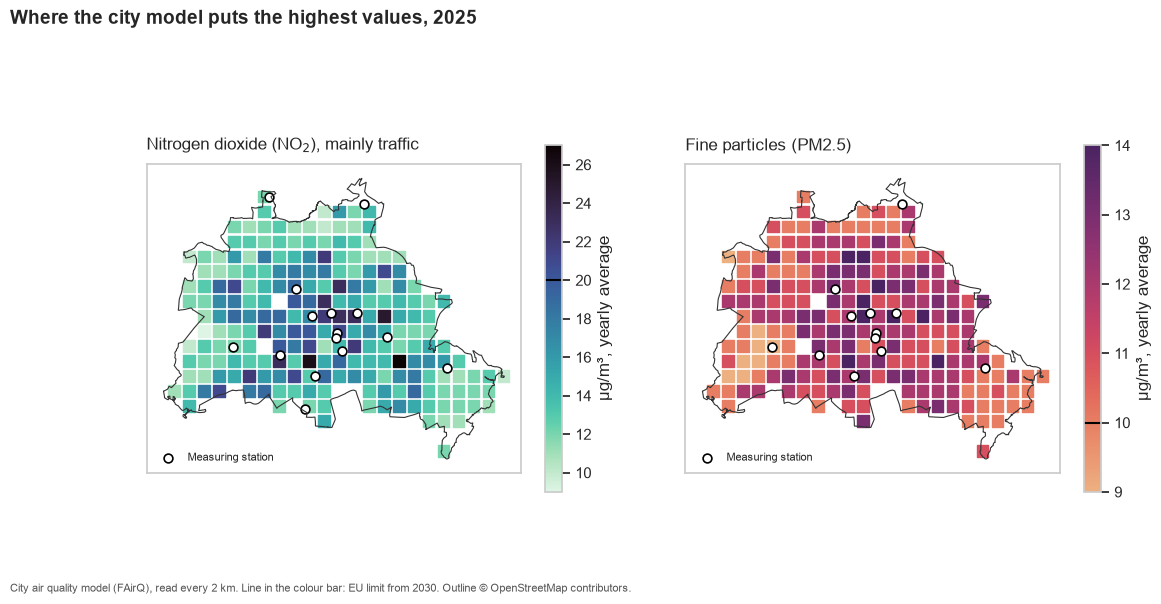

In [39]:
# Where the model puts the highest values, with the measuring stations on top.
# Each square is one sample point standing for 2 x 2 km. The line in the
# colour bar marks the EU limit from 2030.
pts_in = pd.DataFrame([
    {"lat": float(k.split(",")[0]), "lng": float(k.split(",")[1]), **v}
    for (k, v), i in zip(sample.items(), inside) if i
]).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, core in zip(axes, ["no2", "pm2"]):
    sc = ax.scatter(pts_in["lng"], pts_in["lat"], c=pts_in[core], cmap=CMAP[core],
                    marker="s", s=70)
    for part in parts:
        ring = np.array(part[0])
        ax.plot(ring[:, 0], ring[:, 1], color="#333333", lw=0.8)

    has = st.index.isin(ann.loc[ann["core"] == core, "station"])
    ax.scatter(st.loc[has, "lng"], st.loc[has, "lat"], s=40,
               facecolor="white", edgecolor="black", lw=1.2, label="Measuring station")

    cb = fig.colorbar(sc, ax=ax, shrink=0.75, label="µg/m³, yearly average")
    cb.ax.axhline(LIMIT[core], color="black", lw=1.5)

    ax.set_aspect(1 / np.cos(np.radians(52.5)))       # keeps Berlin's true shape
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(PLAIN[core], loc="left", pad=10)
    ax.legend(loc="lower left", fontsize=8, frameon=False)

fig.suptitle("Where the city model puts the highest values, 2025",
             x=0.02, ha="left", fontsize=14, fontweight="bold")
fig.text(0.02, 0.01,
         "City air quality model (FAirQ), read every 2 km. Line in the colour bar: EU limit from 2030. "
         "Outline © OpenStreetMap contributors.",
         fontsize=8, color="#555555")

plt.subplots_adjust(top=0.85, bottom=0.08, wspace=0.15)
plt.savefig(ROOT / "figures" / "04_model_map.png", dpi=150, pad_inches=0.3)

## Findings

### Part A · Interpolation from stations

- Median distance to the nearest station 4.6 km, from 0.6 km (Nansenstr. and
  Karl-Marx-Str.) to 12.7 km (Buch, Frohnau)
- Interpolation smooths toward the middle: clean stations are overestimated,
  traffic stations underestimated, for both pollutants
- NO₂: mean absolute error 7.1 µg/m³, 44 % of the mean. PM2.5: 1.6 µg/m³, 14 %
- Error follows station type, not distance. NO₂ signed error: traffic −5.3,
  background +5.0, suburb +9.9 µg/m³
- Stable across weighting powers 1 to 6
- Nansenstr. and Karl-Marx-Str. are 600 m apart and differ by 7.2 µg/m³ NO₂

### Part B · City model

- Closer than interpolation: NO₂ mean absolute error 3.0 against 7.1,
  PM2.5 1.0 against 1.6
- Its error is almost entirely an offset: +2.9 NO₂, +1.0 PM2.5. It never reads
  below a station. Pattern right, level slightly high
- Schildhornstr. is overestimated by both methods, by 7.8 µg/m³ NO₂ under the model
- Above the EU limit from 2030: [x] of 15 NO₂ stations, [x–x] % of Berlin's area.
  Above the WHO guideline: [x] % of stations, [x–x] % of the area
- A share of stations is not a share of the city: six stations stand at busy
  roads on purpose

## Decisions

- Inverse distance weighting, power 2, annual means. Edge stations are
  extrapolated, kept and named
- Model read through WMS, since the WFS lists no layers. Values are whole numbers
- Area share from a 2 km sample, restricted to Berlin's boundary: [n] points
- Area shown as a range: corrected for the model's offset, and as published
- Colour: hue is pollutant. Pale marks the uncertain part of a range

## Open

- The model is fitted with measurements. Interpolation is the only
  out-of-sample test here
- Why the model reads high is not established
- Area is not population. Where people live is not weighted
- Measuring height is published for 3 of 15 stations. Neither stations nor
  model describe breathing height